# Volcano Eruption Prediction from Earthquake Data

**Real-data implementation of the Stanford CS229 PEEVED project**

This notebook answers two questions:

1. **Classification:** Was Kīlauea erupting when an earthquake occurred?
2. **Regression:** How many days until the next eruption?

**Important:** The notebook downloads the original authors' earthquake catalog and eruption-history files into `../data/raw/`.

Reference: Mullet, Singh & Wong, *Predicting Eruptive Events at Volcanoes from Earthquake Data*, Stanford CS229, 2019.


## 1. Setup and data source

Real files used:

- `puuoo_earthquakes.csv`
- `kilauea_eruptionHistory.xlsx`
- `PuuOo.csv` as a transparent fallback if the workbook schema cannot be parsed

The original authors publish these files in their PEEVED repository.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT))

from src.data import FEATURES, load_real, load_sample, make_synthetic, build_dataset, random_stratified_split, chronological_split
from src.models import fit_and_score_classifiers, fit_and_score_regressors
from src.plots import save_rate_plot, save_feature_importance, save_regression_plot

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

USE_REAL_DATA = True

if USE_REAL_DATA:
    catalog, eruptions = load_real(ROOT / "data" / "raw")
    DATA_SOURCE = "REAL — original PEEVED files"
else:
    catalog, eruptions = load_sample(ROOT / "data")
    DATA_SOURCE = "SYNTHETIC — offline smoke test"

print(DATA_SOURCE)
print("Raw earthquakes:", len(catalog))
print("Eruption episodes:", len(eruptions))


Could not parse eruption workbook (No recognizable start/end eruption sheet found.); using PuuOo.csv fallback.
REAL — original PEEVED files
Raw earthquakes: 6485
Eruption episodes: 49


## 2. Build the ML dataset

For each earthquake we create exactly the paper-style feature set:

- longitude
- latitude
- depth
- magnitude
- number of earthquakes in the previous 1 day
- number in the previous 7 days
- number in the previous 30 days

Targets:

- `erupting`: 0/1
- `tte`: days until the next eruption; 0 during an eruption

The earthquake-rate features use only **previous** events, so the current/future earthquake is not counted.


In [2]:
df = build_dataset(catalog, eruptions)

print("Usable labeled earthquakes:", len(df))
print("Erupting share:", f"{df.erupting.mean():.2%}")
display(df[["time"] + FEATURES + ["erupting", "tte"]].head())


Usable labeled earthquakes: 6485
Erupting share: 14.66%


,time,longitude,latitude,depth,magnitude,rate_1d,rate_7d,rate_30d,erupting,tte
0,1983-01-01 00:18:51,-155.2292,19.3052,6.11,1.92,0,0,0,0,1.986910
1,1983-01-01 00:43:33,-155.1700,19.3628,3.05,2.14,1,1,1,0,1.969757
2,1983-01-01 00:50:44,-155.2425,19.3818,0.98,2.23,2,2,2,0,1.964769
3,1983-01-01 01:25:45,-155.1575,19.3442,8.63,2.25,3,3,3,0,1.940451
4,1983-01-01 01:58:30,-155.0647,19.3343,6.03,1.78,4,4,4,0,1.917708


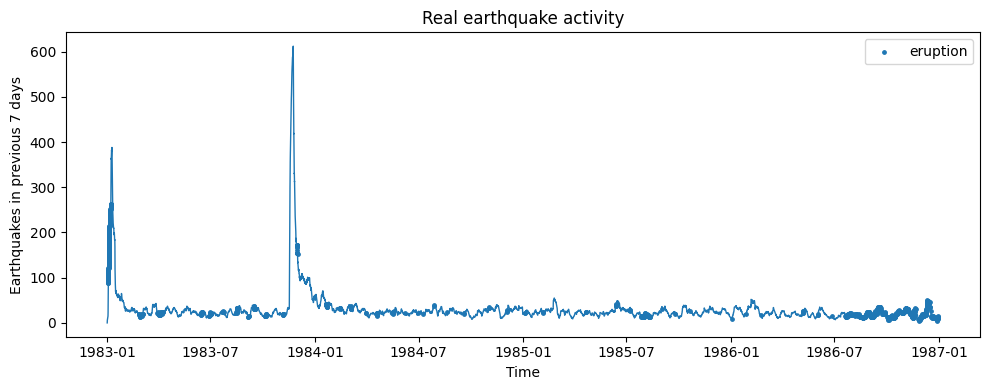

In [3]:
save_rate_plot(df, RESULTS / "earthquake_rate.png")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(df["time"], df["rate_7d"], linewidth=1)
eruption_rows = df[df["erupting"] == 1]
if len(eruption_rows):
    ax.scatter(eruption_rows["time"], eruption_rows["rate_7d"], s=6, label="eruption")
ax.set_xlabel("Time")
ax.set_ylabel("Earthquakes in previous 7 days")
ax.set_title("Real earthquake activity")
ax.legend()
plt.tight_layout()
plt.show()


## 3. Task 1 — contemporaneous eruption classification

We reproduce the paper's model family:

- Logistic Regression
- K-Means classifier
- Random Forest classifier
- Neural Network classifier

The Random Forest's number of trees and depth are selected using the development split.
Metrics:

- AUROC
- Cohen's kappa
- confusion matrix


In [4]:
def run_classification(mode):
    if mode == "random":
        train, dev, test = random_stratified_split(df)
    else:
        train, dev, test = chronological_split(df)

    results, models, scaler, rf_params = fit_and_score_classifiers(
        train, dev, test, FEATURES, split_name=mode
    )
    return train, dev, test, results, models, scaler, rf_params

cls_random = run_classification("random")
cls_chrono = run_classification("chronological")

print("Random-split test results")
display(cls_random[3][cls_random[3].dataset == "test"].round(3))

print("Chronological-split test results")
display(cls_chrono[3][cls_chrono[3].dataset == "test"].round(3))


Random-split test results


,split,model,dataset,threshold,accuracy,precision,recall,f1,kappa,auroc,tn,fp,fn,tp
2,random,Logistic Regression,test,0.588,0.810,0.373,0.432,0.400,0.288,0.795,485,69,54,41
5,random,K-Means,test,0.500,0.549,0.204,0.716,0.317,0.115,0.691,288,266,27,68
8,random,Random Forest,test,0.323,0.900,0.674,0.611,0.641,0.583,0.894,526,28,37,58
11,random,Neural Network,test,0.343,0.880,0.639,0.411,0.500,0.435,0.854,532,22,56,39


Chronological-split test results


,split,model,dataset,threshold,accuracy,precision,recall,f1,kappa,auroc,tn,fp,fn,tp
2,chronological,Logistic Regression,test,0.476,0.519,0.721,0.581,0.643,-0.067,0.458,56,109,203,281
5,chronological,K-Means,test,0.500,0.522,0.731,0.568,0.640,-0.036,0.460,64,101,209,275
8,chronological,Random Forest,test,0.496,0.359,0.715,0.233,0.352,-0.024,0.453,120,45,371,113
11,chronological,Neural Network,test,0.131,0.307,0.685,0.130,0.219,-0.026,0.466,136,29,421,63


In [5]:
rf_cls = cls_random[4]["Random Forest"]
save_feature_importance(
    rf_cls, FEATURES,
    RESULTS / "random_classification_feature_importance.png",
    "Random Forest feature importance — classification"
)

imp = pd.Series(rf_cls.feature_importances_, index=FEATURES).sort_values(ascending=False)
display(imp.to_frame("importance"))


,importance
rate_30d,0.292604
rate_7d,0.178967
longitude,0.122659
depth,0.110649
latitude,0.108347
rate_1d,0.096531
magnitude,0.090243


## 4. Task 2 — time-to-eruption regression

Models:

- K-Means regressor
- Random Forest regressor
- Neural Network regressor

Metrics:

- RMSE
- R²

The target is standardized using the **training set only**. The final prediction plot is converted back to days.


In [6]:
def run_regression(mode):
    if mode == "random":
        train, dev, test = random_stratified_split(df)
    else:
        train, dev, test = chronological_split(df)

    results, models, scaler, target_scaler, rf_params = fit_and_score_regressors(
        train, dev, test, FEATURES
    )
    return train, dev, test, results, models, scaler, target_scaler, rf_params

reg_random = run_regression("random")
reg_chrono = run_regression("chronological")

print("Random-split test results")
display(reg_random[3][reg_random[3].dataset == "test"].round(3))

print("Chronological-split test results")
display(reg_chrono[3][reg_chrono[3].dataset == "test"].round(3))


Random-split test results


,model,dataset,rmse_scaled,rmse_days,r2
2,K-Means,test,1.019,13.764,-0.007
5,Random Forest,test,0.714,9.649,0.505
8,Neural Network,test,0.748,10.104,0.457


Chronological-split test results


,model,dataset,rmse_scaled,rmse_days,r2
2,K-Means,test,0.735,10.597,-2.070
5,Random Forest,test,0.842,12.143,-3.032
8,Neural Network,test,0.844,12.168,-3.049


In [7]:
rf_reg = reg_random[4]["Random Forest"]
save_feature_importance(
    rf_reg, FEATURES,
    RESULTS / "random_regression_feature_importance.png",
    "Random Forest feature importance — regression"
)

save_regression_plot(
    rf_reg, reg_random[5], reg_random[6], reg_random[2], FEATURES,
    RESULTS / "random_regression_predictions.png"
)

display(pd.Series(rf_reg.feature_importances_, index=FEATURES)
        .sort_values(ascending=False).to_frame("importance"))


,importance
rate_30d,0.301948
rate_7d,0.157613
longitude,0.141551
depth,0.108431
latitude,0.106224
rate_1d,0.103324
magnitude,0.080910


## 5. Results and interpretation

Do **not** hard-code expected scores.

The real-data results above are the numbers to report.

Two evaluations are intentionally shown:

### Random split
This reproduces the paper-style 70/20/10 stratified setup.

### Chronological split
This is an additional robustness check: earlier earthquakes train the model and later earthquakes are held out. This matters because nearby earthquakes can be temporally correlated.

### What to look for

- Classification should be evaluated mainly with **AUROC and Cohen's kappa**, not accuracy alone.
- Regression is expected to be substantially harder than contemporaneous classification.
- A low/negative regression R² is a valid result; it means the earthquake-only feature set does not explain much of the variation in time-to-eruption.
- Do not claim that the model can guarantee or precisely forecast an eruption date.

### Reproducibility rule

Only quote metrics produced from the **REAL** dataset. The bundled sample data is for testing that the code works offline.


## 6. Limitations and possible improvements

1. Single-volcano evaluation limits generalization.
2. Earthquake catalogs alone omit important volcanic observables such as deformation and gas measurements.
3. Random splits can overestimate future generalization when events close in time are correlated.
4. The eruption labels depend on the historical eruption source and its temporal resolution.
5. A practical forecasting system would need uncertainty estimates, monitoring latency, and continuous updating.

The strongest next research step is to add independent signals such as deformation or gas data and evaluate on strictly future time periods.
